<a href="https://colab.research.google.com/github/Roman74800/fintech-retention-analytics/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer retention and cohort analysis
Synthetic mobile banking activity; all figures are illustrative.

Cloning into 'fintech-retention-analytics'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 12 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (12/12), 209.21 KiB | 2.01 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Month 1 retention by cohort:
cohort
2025-01    0.804
2025-02    0.753
2025-03    0.753
2025-04    0.714
2025-05    0.757
2025-06    0.749
Name: 1, dtype: float64


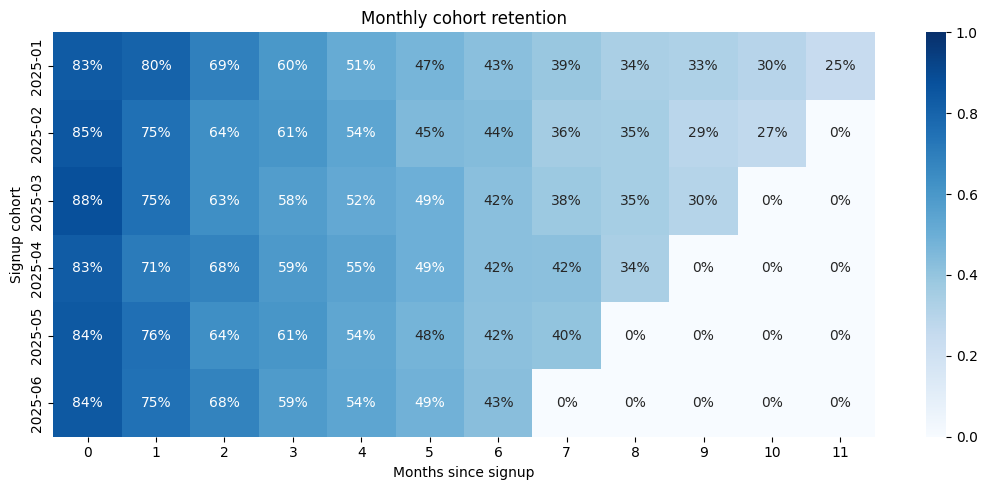

Average transaction volume by acquisition channel:
channel
organic     2402.66
paid        2378.15
referral    2419.77
Name: volume_rub, dtype: float64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
!git clone https://github.com/Roman74800/fintech-retention-analytics.git
base = Path('/content/fintech-retention-analytics')
users=pd.read_csv(base/'users.csv',parse_dates=['signup_month'])
activity=pd.read_csv(base/'monthly_activity.csv',parse_dates=['activity_month'])
joined=activity.merge(users,on='user_id',validate='many_to_one')
joined['cohort']=joined.signup_month.dt.to_period('M').astype(str)
joined['age_months']=(joined.activity_month.dt.year-joined.signup_month.dt.year)*12+joined.activity_month.dt.month-joined.signup_month.dt.month
cohort_sizes=users.groupby(users.signup_month.dt.to_period('M')).user_id.nunique()
active=joined.groupby(['cohort','age_months']).user_id.nunique().unstack(fill_value=0)
retention=active.div(cohort_sizes.rename(index=str),axis=0)
print('Month 1 retention by cohort:')
print(retention.get(1,pd.Series(dtype=float)).round(3))
plt.figure(figsize=(11,5));sns.heatmap(retention,annot=True,fmt='.0%',cmap='Blues',vmin=0,vmax=1);plt.title('Monthly cohort retention');plt.xlabel('Months since signup');plt.ylabel('Signup cohort');plt.tight_layout();plt.show()
print('Average transaction volume by acquisition channel:')
print(joined.groupby('channel').volume_rub.mean().round(2))


## Interpretation
Look for cohort differences in M1 retention and compare acquisition channels. The generating process includes a referral uplift, so these differences are simulated, not causal evidence.